# gpu_corrcal calibration simulation

End-to-end test of the GPU CorrCal likelihood and gradient on simulated data from CHORD or a CHORD-like array.

1. **Array** (`LAYOUT`):
   - `"chord"`: the surveyed CHORD dish positions (centres of the elevation axes, from `elevation_axis_alignment_points_9Jul2025.csv`), converted from UTM Ground to the CHORD topocentric frame (East, North, Up) following Ryan, *CHORD Localization v0.2*. 512 dishes on a 22 x 24 grid with 16 sites empty. `CHORD_COLS` / `CHORD_ROWS` select a sub-block.
   - `"grid"`: an `NX` x `NY` lattice built from the surveyed CHORD separation vectors $\vec{\Delta x}$, $\vec{\Delta y}$ (Ryan, Table 3), including their small cross terms and the tilt of the array plane.
   - `"custom"`: any (N, 3) East/North/Up positions in metres.
2. **Sky**: a Gaussian random field on a HEALPix map, $C_\ell \propto (1+\ell)^{-2}$, plus a power-law point source population, in the topocentric frame. The dishes point at topocentric zenith ($\hat n_{\rm vert} = \hat z_{\rm topo}$, Ryan Table 3).
3. **Visibilities**: a direct sum over sky pixels and sources,
   $V_{12} = \sum_p A(\hat n_p)\, S_p\, e^{-2\pi i\, \mathbf b_{12}\cdot \hat n_p/\lambda}$, with $\mathbf b_{12} = \mathbf x_2 - \mathbf x_1$ (3D, so the tilt of the array plane enters the fringe phase).
   On an exactly redundant layout with identical beams, every baseline in a group sees the same visibility, so only the unique baselines are simulated. Otherwise every baseline is simulated.
4. **Model covariance**: $\Delta$ from `corrcal.models._compute_diffuse_matrix_from_flat_sky`, $\Sigma$ from the brightest sources, $N$ from the radiometer-style noise level.
5. **Calibration**: inject gains, add noise, minimize the CorrCal negative log-likelihood with scipy CG using the GPU (or CPU reference) `nll` and `grad_nll`.

`DATA_MODE = "direct"` uses the direct-sum visibilities, so the covariance model is only an approximation to the data (flat-sky $\Delta$, unmodeled faint sources, no inter-group correlation).
`DATA_MODE = "model"` draws the diffuse visibilities from $\Delta$ itself. That removes the diffuse model mismatch, so any residual beyond noise and the source-catalog effect points at a bug.
`POS_JITTER_M > 0` perturbs the dish positions used to simulate the data while the model keeps the nominal layout, which tests non-redundancy from dish placement errors.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from scipy.optimize import minimize
from scipy.special import j1

from pyuvdata import AiryBeam
from corrcal import models as cc_models   # flat-sky diffuse matrix
from corrcal import utils as cc_utils

warnings.filterwarnings("ignore", category=UserWarning)

try:
    import cupy as cp
    HAVE_CUPY = cp.cuda.runtime.getDeviceCount() > 0
except Exception:
    cp, HAVE_CUPY = None, False
print("CuPy GPU available:", HAVE_CUPY)

CuPy GPU available: True


## Configuration

Cost at full CHORD (`LAYOUT = "chord"`, all 512 dishes): $b_{\max} \approx 236$ m, so `nside = 1024` and about 1.5 M pixels in the 40 deg cap. The direct sum over ~1000 unique baselines takes seconds on the GPU and a few minutes in NumPy; each `synfast` call takes ~10 s. The CPU CorrCal solve is slow at this size, so the CPU comparisons only run up to `MAX_ANT_CPU` antennas.

In [2]:
BACKEND   = "gpu" if HAVE_CUPY else "cpu"   # likelihood/gradient backend: "gpu" or "cpu"
DATA_MODE = "direct"                        # "direct" (direct-sum sky) or "model" (diffuse drawn from Delta)
SEED      = 1

# ---- Array layout ----------------------------------------------------------------------------
LAYOUT = "chord"            # "chord" (surveyed positions), "grid" (NX x NY CHORD lattice), "custom"

# "chord": surveyed elevation-axis points in UTM Ground (Ryan, CHORD Localization v0.2, Sec. 3)
CHORD_CSV  = Path("data/elevation_axis_alignment_points_9Jul2025.csv")
CHORD_COLS = None          # e.g. range(0, 8): E-W grid columns to keep (0 = column "01"); None = all 22
CHORD_ROWS = None          # e.g. range(0, 8): N-S grid rows to keep (0 = row "A"); None = all 24

# "grid": NX x NY lattice with the surveyed CHORD separation vectors (topocentric E, N, U; Ryan Table 3)
NX, NY  = 8, 8
CHORD_DX = np.array([6.300000, -0.000358, -0.045129])   # dish x separation [m]
CHORD_DY = np.array([0.000484,  8.500000,  0.033065])   # dish y separation [m]

# "custom": (N, 3) East/North/Up positions [m], or a path to a .npy / whitespace .txt file
CUSTOM_ANTPOS = None
REDUNDANCY_TOL = 0.05      # [m] baseline quantization for grouping when no grid indices exist

POS_JITTER_M = 0.0         # rms per-axis dish placement error [m] applied to the DATA only (0 = nominal)

DISH_D = 6.0               # dish diameter [m]
FREQ   = 600e6             # observing frequency [Hz]

# ---- Grouping and model ----------------------------------------------------------------------
MIN_BL_LEN     = np.sqrt(2) * DISH_D   # drop baselines whose uv footprints overlap the next group strongly
MIN_GROUP_SIZE = 5
N_EIG          = 1                     # diffuse eigenmodes per Re/Im (only used for non-redundant layouts)

# ---- Sky -------------------------------------------------------------------------------------
MAX_ZA_DEG  = 40.0     # sky cap for the direct sum; the 6 m Airy power beam is ~1e-4 by here
T_MEAN      = 30.0     # monopole [K]; enters the autocorrelation only
T_RMS       = 5.0      # rms of the diffuse fluctuations [K]
N_SRC_TOTAL = 2000     # point sources in the cap (~1400/sr above S_MIN)
S_MIN       = 1.0      # [Jy] minimum flux of the source population
SRC_SLOPE   = 2.5      # dN/dS ~ S^-SRC_SLOPE (Euclidean)
N_SRC_CAL   = 5        # brightest (beam-weighted) sources put into Sigma; <= 20 for the GPU kernels

# ---- Noise, gains, solver --------------------------------------------------------------------
SNR          = 1e4     # noise_amp = |V_auto| / SNR, per visibility
AMP_JITTER   = 0.1     # true |g| ~ N(1, AMP_JITTER^2), phases ~ U(0, 2pi)
INIT_AMP_ERR = 0.10    # initial guess: fractional amplitude error
INIT_PHS_ERR = 0.10    # initial guess: phase error [rad]
PHS_NORM     = 0.1     # width of CorrCal's prior on the mean gain phase
GAIN_SCALE   = 1.0
MAX_RESTARTS = 1       # 1 = a single scipy CG call; >1 restarts CG from its last point until it stops moving
MAX_ANT_CPU  = 256     # CPU solves (comparison, sweep) only up to this many antennas

C_LIGHT, K_B = 299792458.0, 1.380649e-23
LAM = C_LIGHT / FREQ
rng = np.random.default_rng(SEED)

## Array layout and redundant groups

**Surveyed CHORD positions.** Each CSV row gives the East and West ends of a dish's elevation axis in UTM Ground coordinates (Easting, Northing, elevation; metres, scale 1). The dish position is the midpoint. UTM Ground is rotated from the topocentric frame by the UTM convergence $\gamma_m = -1.98814^\circ$ about the vertical (Ryan Eqs. 9 to 12):

$\vec x_{\rm topo} = R^{\rm UTM}_{\rm topo}(\vec x_{\rm UTM} - \vec x_{m,\rm UTM})$, with $R^{\rm UTM}_{\rm topo} = (R^{\rm topo}_{\rm UTM})^T$ and $R^{\rm topo}_{\rm UTM} = \begin{pmatrix}\cos\gamma_m & -\sin\gamma_m & 0\\ \sin\gamma_m & \cos\gamma_m & 0 \\ 0 & 0 & 1\end{pmatrix}$.

The DishID gives the grid index: the letter is the N-S row (A = 0), the number the E-W column (01 = 0). Positions are then shifted so the south-west dish (A01, the Grid origin) is at the origin; baselines are unchanged by the shift.

**Redundant groups.** When grid indices exist, baselines are grouped by their integer grid offset $(\Delta i, \Delta j)$, which is exact for a lattice. Otherwise baselines are grouped by quantizing their E, N components to `REDUNDANCY_TOL`. Each pair is ordered so its offset lies in the half plane $\Delta j > 0$ or $(\Delta j = 0, \Delta i > 0)$. The spread of the baseline vectors within each group decides whether the layout is treated as exactly redundant (spread $< 10^{-3}\lambda$).

LAYOUT='chord': 512 antennas, 130268 baselines in 970 groups, group sizes 5-488, b_max = 222.9 m
max baseline spread within a group = 0.132 mm -> exactly redundant
array-plane height range: -0.857 to +0.727 m


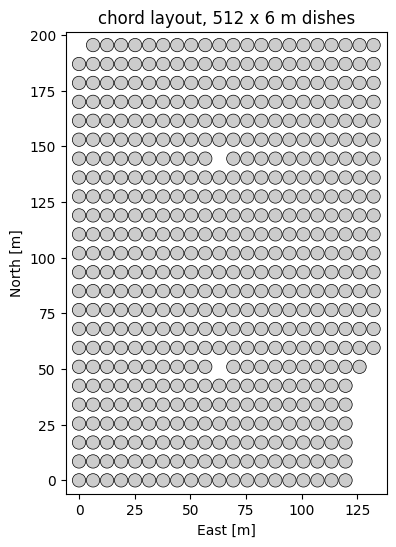

In [3]:
UTM_MARKER = np.array([309551.114, 5466417.524, 545.454])   # DRAO geodetic marker in UTM Ground [m] (Ryan Table 1, Sec. 1)
UTM_CONVERGENCE_DEG = -1.98814                               # gamma_m (Ryan Table 1)


def load_chord_layout(csv_path, cols=None, rows=None):
    data = np.genfromtxt(csv_path, delimiter=",", names=True, dtype=None, encoding="utf-8")
    names = np.array(data["DishID"])
    utm = np.column_stack([0.5 * (data["P_Ex"] + data["P_Wx"]),     # elevation-axis centre
                           0.5 * (data["P_Ey"] + data["P_Wy"]),
                           data["Pz"]])
    g = np.deg2rad(UTM_CONVERGENCE_DEG)
    R_utm_to_topo = np.array([[np.cos(g), np.sin(g), 0.0],
                              [-np.sin(g), np.cos(g), 0.0],
                              [0.0, 0.0, 1.0]])                      # transpose of Ryan Eq. 11
    topo = (utm - UTM_MARKER) @ R_utm_to_topo.T
    grid_ij = np.column_stack([[int(n[1:]) - 1 for n in names],       # column (E-W) index
                               [ord(n[0]) - ord("A") for n in names]]) # row (N-S) index
    keep = np.ones(len(names), bool)
    if cols is not None:
        keep &= np.isin(grid_ij[:, 0], list(cols))
    if rows is not None:
        keep &= np.isin(grid_ij[:, 1], list(rows))
    return topo[keep], grid_ij[keep], names[keep]


def make_grid(nx, ny, dx_vec, dy_vec):
    grid_ij = np.stack(np.meshgrid(np.arange(nx), np.arange(ny), indexing="ij"), -1).reshape(-1, 2)
    antpos = grid_ij[:, :1] * dx_vec + grid_ij[:, 1:] * dy_vec      # Ryan Eq. 1
    return antpos.astype(float), grid_ij


def make_groups(antpos, grid_ij, min_len, min_size, tol):
    a, b = np.triu_indices(len(antpos), 1)
    if grid_ij is not None:
        off = (grid_ij[b] - grid_ij[a]).astype(np.int64)
    else:
        off = np.round((antpos[b] - antpos[a])[:, :2] / tol).astype(np.int64)
    flip = (off[:, 1] < 0) | ((off[:, 1] == 0) & (off[:, 0] < 0))
    off[flip] *= -1
    a, b = np.where(flip, b, a), np.where(flip, a, b)                # ant_2 - ant_1 is the canonical offset

    keys, inv, counts = np.unique(off, axis=0, return_inverse=True, return_counts=True)
    inv = inv.reshape(-1)
    bl = antpos[b] - antpos[a]
    ubl = np.zeros((len(keys), 3))
    np.add.at(ubl, inv, bl)
    ubl /= counts[:, None]                                         # mean baseline of each group

    length = np.linalg.norm(ubl, axis=1)
    kept = np.flatnonzero((length >= min_len) & (counts >= min_size))
    kept = kept[np.argsort(length[kept], kind="stable")]           # groups ordered by baseline length
    rank = np.full(len(keys), -1)
    rank[kept] = np.arange(len(kept))

    sel = rank[inv] >= 0
    order = np.argsort(rank[inv][sel], kind="stable")
    ant_1, ant_2 = a[sel][order], b[sel][order]
    grp_of_bl = rank[inv][sel][order]
    edges = 2 * np.concatenate([[0], np.cumsum(counts[kept])])     # Re/Im-split row edges
    ubl = ubl[kept]
    spread = np.linalg.norm(antpos[ant_2] - antpos[ant_1] - ubl[grp_of_bl], axis=1).max()
    return ant_1, ant_2, edges, ubl, grp_of_bl, spread


if LAYOUT == "chord":
    antpos, grid_ij, dish_names = load_chord_layout(CHORD_CSV, CHORD_COLS, CHORD_ROWS)
elif LAYOUT == "grid":
    antpos, grid_ij = make_grid(NX, NY, CHORD_DX, CHORD_DY)
    dish_names = np.array([f"{chr(ord('A') + j)}{i + 1:02d}" for i, j in grid_ij])
elif LAYOUT == "custom":
    antpos = np.asarray(np.load(CUSTOM_ANTPOS) if str(CUSTOM_ANTPOS).endswith(".npy")
                        else np.loadtxt(CUSTOM_ANTPOS) if isinstance(CUSTOM_ANTPOS, (str, Path))
                        else CUSTOM_ANTPOS, dtype=float)
    grid_ij, dish_names = None, np.arange(len(antpos)).astype(str)
else:
    raise ValueError(LAYOUT)

origin = antpos[np.lexsort((grid_ij[:, 1], grid_ij[:, 0]))[0]] if grid_ij is not None else antpos.min(axis=0)
antpos = antpos - origin                                           # south-west dish at the origin

ant_1, ant_2, edges, ubl, grp_of_bl, spread = make_groups(antpos, grid_ij, MIN_BL_LEN, MIN_GROUP_SIZE,
                                                          REDUNDANCY_TOL)
n_ant, n_bl, n_grp = len(antpos), len(ant_1), len(ubl)
EXACT_REDUNDANT = spread < 1e-3 * LAM

# Dish positions used to simulate the data (nominal unless POS_JITTER_M > 0).
data_antpos = antpos + rng.normal(0.0, POS_JITTER_M, antpos.shape) if POS_JITTER_M > 0 else antpos

b_max = np.linalg.norm(ubl, axis=1).max()
print(f"LAYOUT={LAYOUT!r}: {n_ant} antennas, {n_bl} baselines in {n_grp} groups, "
      f"group sizes {np.diff(edges).min()//2}-{np.diff(edges).max()//2}, b_max = {b_max:.1f} m")
print(f"max baseline spread within a group = {1e3 * spread:.3f} mm -> "
      f"{'exactly redundant' if EXACT_REDUNDANT else 'NOT exactly redundant: every baseline is simulated'}"
      + (f"; data use dish positions jittered by {1e3 * POS_JITTER_M:.1f} mm rms" if POS_JITTER_M > 0 else ""))
print(f"array-plane height range: {antpos[:, 2].min():+.3f} to {antpos[:, 2].max():+.3f} m")

fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(PatchCollection([plt.Circle((x, y), DISH_D / 2) for x, y, _ in antpos],
                                  facecolor="0.8", edgecolor="k", linewidth=0.5))
if n_ant <= 150:
    for (x, y, _), nm in zip(antpos, dish_names):
        ax.text(x, y, nm, ha="center", va="center", fontsize=6)
ax.set_xlim(antpos[:, 0].min() - DISH_D, antpos[:, 0].max() + DISH_D)
ax.set_ylim(antpos[:, 1].min() - DISH_D, antpos[:, 1].max() + DISH_D)
ax.set_aspect("equal"); ax.set_xlabel("East [m]"); ax.set_ylabel("North [m]")
ax.set_title(f"{LAYOUT} layout, {n_ant} x {DISH_D:.0f} m dishes");

## Sky model

The HEALPix map is treated as already in the topocentric horizon frame (pixel colatitude = zenith angle, azimuth measured from East toward North). For a single snapshot of a statistically isotropic field this is equivalent to any celestial orientation.

The pixel size must resolve the fringe on the longest baseline, $\theta_{\rm pix} < \lambda / (2 b_{\max})$, which sets `nside`. Only pixels in the `MAX_ZA_DEG` cap are generated as direction vectors. The monopole is subtracted before the direct sum: the Airy power beam's uv footprint has support $|\mathbf u| \le D/\lambda$, and every calibration baseline has $|\mathbf u| \ge \sqrt2 D/\lambda$, so the true monopole response is zero; summing it over a truncated cap would only add an edge artifact.

nside = 1024 (0.057 deg pixels), 1,470,612 pixels in the 40 deg cap, synfast 0.4 s
brightest apparent fluxes [Jy]: [1.83 1.78 1.76 1.52 1.38]; calibration sources hold 36% of the apparent source flux


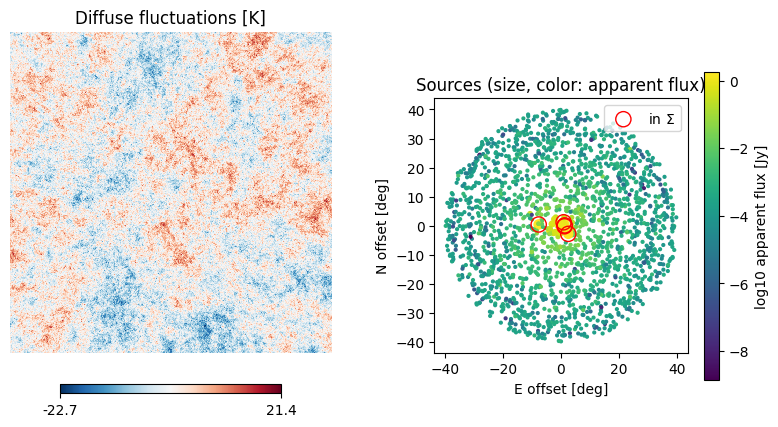

In [4]:
nside = 1 << int(np.ceil(np.log2(np.sqrt(4 * np.pi / 12) / (LAM / (2 * b_max)))))
lmax_map = 3 * nside - 1
pix_area = hp.nside2pixarea(nside)
jy_per_k = 2 * K_B / LAM**2 * 1e26          # [Jy / sr / K]

def airy_power(za):
    x = np.pi * DISH_D * np.sin(za) / LAM
    safe = np.where(x > 1e-12, x, 1.0)
    return np.where(x > 1e-12, (2 * j1(safe) / safe) ** 2, 1.0)

cap_pix = hp.query_disc(nside, [0.0, 0.0, 1.0], np.deg2rad(MAX_ZA_DEG))
pix_za, pix_az = hp.pix2ang(nside, cap_pix)
pix_nhat = np.array([np.sin(pix_za) * np.cos(pix_az), np.sin(pix_za) * np.sin(pix_az), np.cos(pix_za)])
pix_beam = airy_power(pix_za)

# Diffuse angular power spectrum, normalized so the map rms is T_RMS (no monopole: C_0 = 0).
ells = np.arange(lmax_map + 1.0)
cl_shape = 1.0 / (1.0 + ells) ** 2
cl_shape[0] = 0.0
cl_K = cl_shape * T_RMS**2 / np.sum((2 * ells + 1) / (4 * np.pi) * cl_shape)   # [K^2]

t0 = time.perf_counter()
T_map = hp.synfast(cl_K, nside)               # fluctuations only, mean ~ 0
print(f"nside = {nside} ({np.rad2deg(hp.nside2resol(nside)):.3f} deg pixels), "
      f"{cap_pix.size:,} pixels in the {MAX_ZA_DEG:.0f} deg cap, synfast {time.perf_counter() - t0:.1f} s")

# Point sources: area-uniform in the cap, Pareto fluxes with dN/dS ~ S^-SRC_SLOPE.
cos_za = rng.uniform(np.cos(np.deg2rad(MAX_ZA_DEG)), 1.0, N_SRC_TOTAL)
src_za, src_az = np.arccos(cos_za), rng.uniform(0, 2 * np.pi, N_SRC_TOTAL)
src_nhat = np.array([np.sin(src_za) * np.cos(src_az), np.sin(src_za) * np.sin(src_az), np.cos(src_za)])
src_flux = S_MIN * rng.uniform(size=N_SRC_TOTAL) ** (-1.0 / (SRC_SLOPE - 1.0))
src_app = airy_power(src_za) * src_flux       # beam-weighted (apparent) flux
cal_idx = np.argsort(src_app)[::-1][:N_SRC_CAL]
print(f"brightest apparent fluxes [Jy]: {np.round(src_app[cal_idx], 2)}; "
      f"calibration sources hold {src_app[cal_idx].sum() / src_app.sum():.0%} of the apparent source flux")

fig = plt.figure(figsize=(9, 4))
hp.gnomview(T_map, rot=(0, 90), xsize=600, reso=2 * MAX_ZA_DEG * 60 / 600, fig=fig.number,
            sub=(1, 2, 1), title="Diffuse fluctuations [K]", cmap="RdBu_r", notext=True)
ax = fig.add_subplot(1, 2, 2)
sc = ax.scatter(np.rad2deg(src_za) * np.cos(src_az), np.rad2deg(src_za) * np.sin(src_az),
                s=4 + 40 * src_app / src_app.max(), c=np.log10(src_app), cmap="viridis")
ax.scatter(np.rad2deg(src_za[cal_idx]) * np.cos(src_az[cal_idx]),
           np.rad2deg(src_za[cal_idx]) * np.sin(src_az[cal_idx]), s=120, fc="none", ec="r", label="in $\\Sigma$")
ax.set_aspect("equal"); ax.set_xlabel("E offset [deg]"); ax.set_ylabel("N offset [deg]")
ax.set_title("Sources (size, color: apparent flux)"); ax.legend(loc="upper right")
fig.colorbar(sc, ax=ax, label="log10 apparent flux [Jy]");

## Visibility simulation

`direct_sum` evaluates $V_b = \sum_p w_p\, e^{-2\pi i\, \mathbf b\cdot\hat n_p/\lambda}$ in pixel chunks sized to keep the (baselines x pixels) phase array near `CHUNK_ELEMS` entries. It runs on CuPy when available.

`simulate` returns one visibility per calibration baseline. For an exactly redundant layout with nominal positions it evaluates the unique baselines and broadcasts; otherwise it evaluates every baseline from the given dish positions. Rows of the covariance and data vectors alternate Re/Im, as in CorrCal.

In [5]:
CHUNK_ELEMS = 2 ** 23

def direct_sum(bl, nhat, weights):
    xp = cp if HAVE_CUPY else np
    chunk = max(256, CHUNK_ELEMS // max(len(bl), 1))
    bl_l = xp.asarray(bl / LAM)
    V = xp.zeros(len(bl), dtype=complex)
    for s in range(0, weights.size, chunk):
        ph = bl_l @ xp.asarray(nhat[:, s:s + chunk])
        V += xp.exp(-2j * np.pi * ph) @ xp.asarray(weights[s:s + chunk])
    return cp.asnumpy(V) if HAVE_CUPY else V


def simulate(nhat, weights, positions=None):
    if positions is None and EXACT_REDUNDANT:
        return direct_sum(ubl, nhat, weights)[grp_of_bl]
    pos = antpos if positions is None else positions
    return direct_sum(pos[ant_2] - pos[ant_1], nhat, weights)


def split_re_im(z):
    out = np.empty(2 * z.size)
    out[0::2], out[1::2] = z.real, z.imag
    return out


data_pos = data_antpos if POS_JITTER_M > 0 else None
diff_weights = lambda T: pix_beam * T[cap_pix] * jy_per_k * pix_area

t0 = time.perf_counter()
V_diff_bl = simulate(pix_nhat, diff_weights(T_map), data_pos)      # data: diffuse
V_src_bl = simulate(src_nhat, src_app, data_pos)                   # data: all sources
V_cal_bl = np.stack([simulate(src_nhat[:, [j]], src_app[[j]]) for j in cal_idx], axis=1)  # model: Sigma sources
print(f"direct sum: {time.perf_counter() - t0:.1f} s")

# Autocorrelation (zero spacing) including the monopole, for the noise level.
V_auto = np.sum(pix_beam * (T_map[cap_pix] + T_MEAN)) * jy_per_k * pix_area + src_app.sum()
print(f"V_auto = {V_auto:.1f} Jy;  rms |V| diffuse = {np.sqrt(np.mean(np.abs(V_diff_bl)**2)):.3f} Jy, "
      f"sources = {np.sqrt(np.mean(np.abs(V_src_bl)**2)):.3f} Jy")

direct sum: 1.0 s
V_auto = 2776.0 Jy;  rms |V| diffuse = 5.543 Jy, sources = 4.580 Jy


## Model covariance

**Diffuse matrix.** For an exactly redundant group of $n$ baselines with identical beams, the $2n\times 2n$ Re/Im covariance block is $\tfrac{\sigma_r^2}{2}\,\mathbf 1\mathbf 1^T \otimes I_2$, which has rank 2. Its $\Delta$ rows are therefore identical across the group and equal to those of a single baseline. `diffuse_matrix_redundant` calls the flat-sky helper with one representative baseline per group and broadcasts, which gives the same $\Delta\Delta^T$ as the full call at a fraction of the cost (the full call does a dense $2n\times2n$ `eigh` and an $(n_{lm}, n, n)$ harmonic sum per group). For a layout that is not exactly redundant, the full helper is called with `N_EIG` modes.

The helper's group band power is $\sum_\ell (2\ell+1) C_\ell\, j_\ell(2\pi|\mathbf u|)^2$, so $C_\ell$ must extend past $2\pi|\mathbf u|_{\max}$; it is extended as $\ell^{-2}$ beyond the map's $\ell_{\max}$.

**Source matrix.** Column $j$ is the Re/Im-split visibility of calibration source $j$ alone, from the nominal dish positions.

**Units.** Everything is divided by the per-row noise standard deviation, so $N = I$. The likelihood changes by a constant, and the float32 kernels see O(1) numbers.

In [6]:
def diffuse_matrix_redundant(cl_jy, beam, edges, ant_1, ant_2, antpos):
    reps = edges[:-1] // 2                                   # first baseline of each group
    one_edges = 2 * np.arange(len(reps) + 1)
    diff_one = cc_models._compute_diffuse_matrix_from_flat_sky(
        cl_jy, 64, beam, FREQ, antpos, ant_1[reps], ant_2[reps], one_edges,
        n_eig=1, bl_convention="j-i")                        # u = (x_2 - x_1) / lambda, as in direct_sum
    rows = np.repeat(np.arange(len(reps)), np.diff(edges) // 2)
    diff = np.empty((edges[-1], diff_one.shape[1]))
    diff[0::2] = diff_one[2 * rows]
    diff[1::2] = diff_one[2 * rows + 1]
    return diff


lmax_cov = int(np.ceil(2 * np.pi * b_max / LAM * 1.3)) + 50
cl_jy = np.zeros(max(lmax_cov, lmax_map) + 1)
cl_jy[:lmax_map + 1] = cl_K * jy_per_k**2
tail = np.arange(lmax_map + 1, cl_jy.size)
cl_jy[tail] = cl_jy[lmax_map] * ((1.0 + lmax_map) / (1.0 + tail)) ** 2

t0 = time.perf_counter()
beam = AiryBeam(diameter=DISH_D)
if EXACT_REDUNDANT:
    diff_mat_jy = diffuse_matrix_redundant(cl_jy, beam, edges, ant_1, ant_2, antpos)
else:
    diff_mat_jy = cc_models._compute_diffuse_matrix_from_flat_sky(
        cl_jy, 64, beam, FREQ, antpos, ant_1, ant_2, edges, n_eig=N_EIG, bl_convention="j-i")
src_mat_jy = np.stack([split_re_im(V_cal_bl[:, j]) for j in range(N_SRC_CAL)], axis=1)
print(f"Delta {diff_mat_jy.shape}, Sigma {src_mat_jy.shape}, built in {time.perf_counter() - t0:.1f} s")

def normalized_model(snr):
    # noise_amp = |V_auto| / snr is the |V| noise per visibility; each Re or Im row gets noise_amp / sqrt(2).
    sigma_row = (V_auto / snr) / np.sqrt(2)
    return diff_mat_jy / sigma_row, src_mat_jy / sigma_row, sigma_row


diff_mat, src_mat, sigma_row = normalized_model(SNR)
noise = np.ones(edges[-1])

Delta (260536, 2), Sigma (260536, 5), built in 5.6 s


### Check: $\Delta$ against Monte Carlo

Per baseline, the model predicts $\langle |V|^2\rangle = \|\Delta_{\rm Re\,row}\|^2 + \|\Delta_{\rm Im\,row}\|^2$. Averaging $|V|^2$ over `N_MC` independent sky realizations through `simulate` (nominal positions), then over each group, should give ratios scattered around 1 with fractional scatter $\approx 1/\sqrt{N_{\rm MC}}$. The flat-sky band power and the ignored pixel window bias the ratio at the ~10% level, which is acceptable model mismatch for a covariance. Set `N_MC = 0` to skip; each realization costs one `synfast` call.

3 realizations in 3.2 s; MC/model median 0.775, mean 0.877


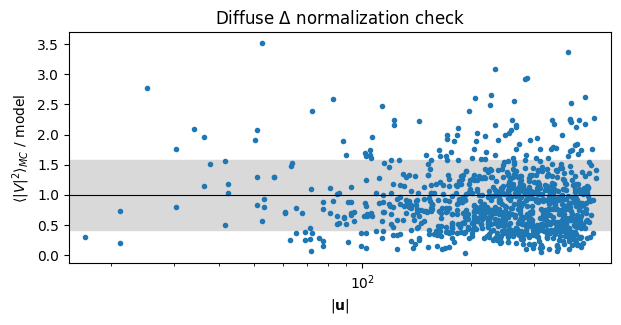

In [7]:
N_MC = 20 if nside <= 256 else 3
if N_MC:
    t0 = time.perf_counter()
    var_mc_bl = np.mean([np.abs(simulate(pix_nhat, diff_weights(hp.synfast(cl_K, nside)))) ** 2
                         for _ in range(N_MC)], axis=0)
    var_model_bl = np.sum(diff_mat_jy[0::2] ** 2, 1) + np.sum(diff_mat_jy[1::2] ** 2, 1)
    per_group = lambda v: np.bincount(grp_of_bl, v) / np.bincount(grp_of_bl)
    ratio = per_group(var_mc_bl) / per_group(var_model_bl)
    print(f"{N_MC} realizations in {time.perf_counter() - t0:.1f} s; "
          f"MC/model median {np.median(ratio):.3f}, mean {ratio.mean():.3f}")

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.semilogx(np.linalg.norm(ubl, axis=1) / LAM, ratio, "o", ms=3)
    ax.axhline(1, color="k", lw=0.8)
    ax.fill_between([1, 1e4], 1 - 1 / np.sqrt(N_MC), 1 + 1 / np.sqrt(N_MC), color="0.85", zorder=0)
    ax.set_xlim(0.9 * np.linalg.norm(ubl, axis=1).min() / LAM, 1.1 * b_max / LAM)
    ax.set_xlabel(r"$|\mathbf{u}|$"); ax.set_ylabel(r"$\langle|V|^2\rangle_{MC}$ / model")
    ax.set_title(r"Diffuse $\Delta$ normalization check");

## Gains and data

True gains: $|g| \sim \mathcal N(1, 0.1^2)$, phases uniform on $[0, 2\pi)$. The initial guess perturbs them by `INIT_AMP_ERR` and `INIT_PHS_ERR`, as in the CorrCal tutorial. The data are $d_{12} = g_1 g_2^* V_{12} + n_{12}$.

In [8]:
def draw_gains(rng):
    amp = rng.normal(1.0, AMP_JITTER, n_ant)
    phs = rng.uniform(0, 2 * np.pi, n_ant)
    true = amp * np.exp(1j * phs)
    init = amp * rng.normal(1.0, INIT_AMP_ERR, n_ant) * np.exp(1j * (phs + rng.normal(0, INIT_PHS_ERR, n_ant)))
    return true, init


def make_data(true_gains, rng, diff_mat, sigma_row, mode=DATA_MODE):
    if mode == "direct":
        sky = split_re_im(V_diff_bl + V_src_bl) / sigma_row
    elif mode == "model":
        # Diffuse part drawn from Delta itself: independent N(0, I) amplitudes per group.
        z = rng.standard_normal((n_grp, diff_mat.shape[1]))
        sky = np.einsum("rk,rk->r", diff_mat, z[np.repeat(np.arange(n_grp), np.diff(edges))])
        sky += split_re_im(V_src_bl) / sigma_row
    else:
        raise ValueError(mode)
    sky_c = sky[0::2] + 1j * sky[1::2]
    gained = true_gains[ant_1] * np.conj(true_gains[ant_2]) * sky_c
    return split_re_im(gained) + rng.standard_normal(2 * n_bl)   # N = I after normalization


true_gains, init_gains = draw_gains(rng)
data = make_data(true_gains, rng, diff_mat, sigma_row)
print(f"data rows: {data.size}, median |d| / sigma = {np.median(np.abs(data)):.1f}")

data rows: 260536, median |d| / sigma = 14.3


## Calibration

Both backends expose `nll(gains, cov, data, ant_1, ant_2, scale, phs_norm_fac)`. The GPU `grad_nll` additionally takes a `GradWorkspace`, built once per solve. scipy passes the same `args` to `fun` and `jac`, so the two are wrapped in closures. One warm-up call of each is made before the timer starts, so CuPy's first-call kernel compilation is not timed.

scipy CG ends with "precision loss" once the decrease in $f$ per line-search step falls below the rounding noise in $f$. With `MAX_RESTARTS > 1`, CG is restarted from its last point (discarding its previous search direction) until a restart makes no progress.

In [9]:
def to_host(x):
    return cp.asnumpy(x) if (HAVE_CUPY and isinstance(x, cp.ndarray)) else np.asarray(x)


def build_objective(backend, data, diff_mat, src_mat):
    if backend == "gpu":
        from gpu_corrcal.sparse import GpuSparseCov
        from gpu_corrcal.optimize import nll, grad_nll
        from gpu_corrcal.linalg import GradWorkspace
        cov = GpuSparseCov(noise, src_mat, diff_mat, edges, n_eig=diff_mat.shape[1])
        d = cp.ascontiguousarray(cp.asarray(data, dtype=cp.float32))
        a1, a2 = cp.asarray(ant_1, dtype=cp.int32), cp.asarray(ant_2, dtype=cp.int32)
        gws = GradWorkspace(a1, a2, n_ant, cov.n_grp, cov.n_eig, cov.n_src)
        fun = lambda g: float(nll(g, cov, d, a1, a2, GAIN_SCALE, PHS_NORM))
        jac = lambda g: to_host(grad_nll(g, cov, d, a1, a2, GAIN_SCALE, PHS_NORM, gws)).astype(np.float64)
    elif backend == "cpu":
        from corrcal.sparse import SparseCov
        from corrcal.optimize import nll, grad_nll
        cov = SparseCov(noise=noise, src_mat=src_mat, diff_mat=diff_mat, edges=edges,
                        n_eig=diff_mat.shape[1], isinv=False)
        a1, a2 = ant_1.astype(np.int64), ant_2.astype(np.int64)
        fun = lambda g: nll(g, cov, data, a1, a2, GAIN_SCALE, PHS_NORM)
        jac = lambda g: grad_nll(g, cov, data, a1, a2, GAIN_SCALE, PHS_NORM)
    else:
        raise ValueError(backend)
    return fun, jac


def calibrate(backend, data, init_gains, diff_mat, src_mat, maxiter=2000, max_restarts=MAX_RESTARTS):
    fun, jac = build_objective(backend, data, diff_mat, src_mat)
    x = GAIN_SCALE * split_re_im(init_gains)
    fun(x); jac(x)                                           # warm-up, not timed
    t0, nit, nfev, njev = time.perf_counter(), 0, 0, 0
    for _ in range(max_restarts):
        res = minimize(fun, x, jac=jac, method="CG", options={"maxiter": maxiter})
        nit, nfev, njev = nit + res.nit, nfev + res.nfev, njev + res.njev
        x = res.x
        if res.nit <= 1:                                     # a fresh start made no progress
            break
    res.nit, res.nfev, res.njev = nit, nfev, njev
    wall = time.perf_counter() - t0
    return (x[0::2] + 1j * x[1::2]) / GAIN_SCALE, res, wall


fit_gains, res, wall = calibrate(BACKEND, data, init_gains, diff_mat, src_mat)
print(f"[{BACKEND}] {res.message}  nit={res.nit}  nfev={res.nfev}  njev={res.njev}  "
      f"wall={wall:.2f} s ({1e3 * wall / (res.nfev + res.njev):.2f} ms per call)")

[gpu] Desired error not necessarily achieved due to precision loss.  nit=8  nfev=49  njev=39  wall=0.08 s (0.96 ms per call)


## Results

Gains are compared after rephasing both sets to antenna 0. CorrCal leaves an overall amplitude and a linear phase gradient across the array poorly constrained when the source catalog is incomplete (Pascua, Sievers & Liu 2026, Sec. 5.4). `degenerate_fit` removes the best-fit $\ln|g|$ offset and phase plane $\phi_0 + \mathbf k\cdot\mathbf x$ from $g_{\rm fit}/g_{\rm true}$; the remainder is the non-degenerate calibration error.

amplitude offset +1.63e-02, phase slope (E, N) = [3.13501354e-05 4.44464474e-05] rad/m
rms after removing degenerate modes: amp 1.25e-03 (init 1.00e-01), phase 1.21e-03 rad (init 1.03e-01)


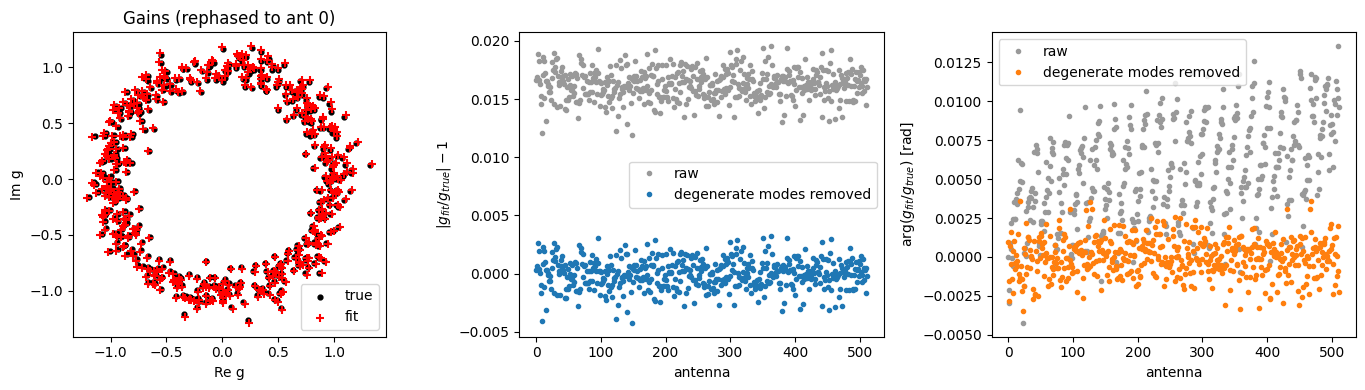

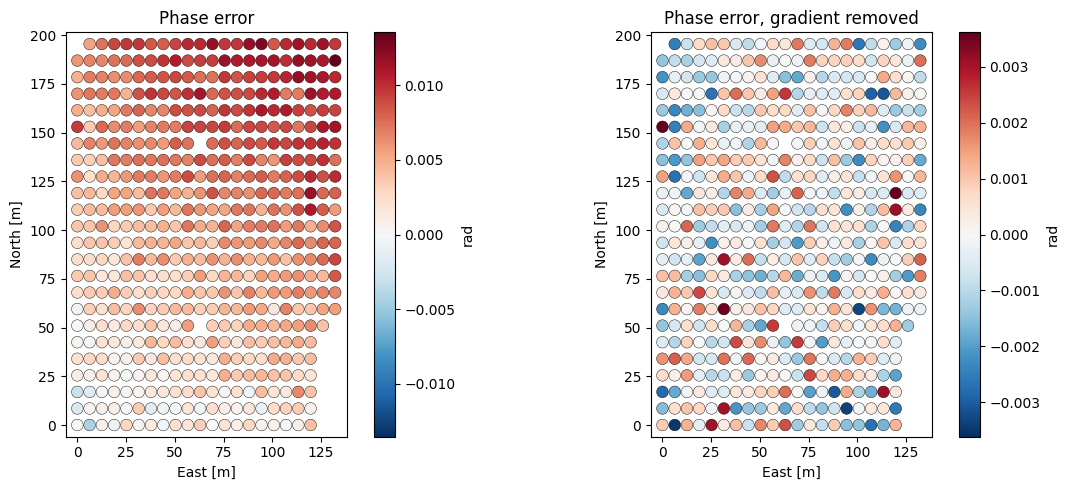

In [10]:
def degenerate_fit(fit, true, antpos):
    r = cc_utils.rephase_to_ant(fit, 0) / cc_utils.rephase_to_ant(true, 0)
    log_amp, phs = np.log(np.abs(r)), np.angle(r)
    A = np.column_stack([np.ones(len(r)), antpos[:, 0], antpos[:, 1]])
    coef, *_ = np.linalg.lstsq(A, phs, rcond=None)
    return {
        "amp_raw": np.abs(r) - 1, "phs_raw": phs,
        "amp_res": np.exp(log_amp - log_amp.mean()) - 1, "phs_res": phs - A @ coef,
        "amp_offset": np.exp(log_amp.mean()) - 1, "phs_slope": coef[1:],
    }


err = degenerate_fit(fit_gains, true_gains, antpos)
err0 = degenerate_fit(init_gains, true_gains, antpos)
rms = lambda x: np.sqrt(np.mean(x ** 2))
print(f"amplitude offset {err['amp_offset']:+.2e}, phase slope (E, N) = {err['phs_slope']} rad/m")
print(f"rms after removing degenerate modes: amp {rms(err['amp_res']):.2e} (init {rms(err0['amp_res']):.2e}), "
      f"phase {rms(err['phs_res']):.2e} rad (init {rms(err0['phs_res']):.2e})")

g_t = cc_utils.rephase_to_ant(true_gains, 0)
g_f = cc_utils.rephase_to_ant(fit_gains, 0)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(g_t.real, g_t.imag, c="k", s=12, label="true")
axes[0].scatter(g_f.real, g_f.imag, marker="+", c="r", s=40, label="fit")
axes[0].set_aspect("equal"); axes[0].legend(); axes[0].set_title("Gains (rephased to ant 0)")
axes[0].set_xlabel("Re g"); axes[0].set_ylabel("Im g")

axes[1].plot(err["amp_raw"], ".", c="0.6", label="raw")
axes[1].plot(err["amp_res"], ".", c="C0", label="degenerate modes removed")
axes[1].set_xlabel("antenna"); axes[1].set_ylabel(r"$|g_{fit}/g_{true}| - 1$"); axes[1].legend()

axes[2].plot(err["phs_raw"], ".", c="0.6", label="raw")
axes[2].plot(err["phs_res"], ".", c="C1", label="degenerate modes removed")
axes[2].set_xlabel("antenna"); axes[2].set_ylabel(r"arg$(g_{fit}/g_{true})$ [rad]"); axes[2].legend()
fig.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, key, title in zip(axes, ["phs_raw", "phs_res"], ["Phase error", "Phase error, gradient removed"]):
    v = np.abs(err[key]).max()
    dishes = PatchCollection([plt.Circle((x, y), DISH_D / 2) for x, y, _ in antpos],
                             cmap="RdBu_r", edgecolor="k", linewidth=0.3)
    dishes.set_array(err[key]); dishes.set_clim(-v, v)
    ax.add_collection(dishes)
    ax.set_xlim(antpos[:, 0].min() - DISH_D, antpos[:, 0].max() + DISH_D)
    ax.set_ylim(antpos[:, 1].min() - DISH_D, antpos[:, 1].max() + DISH_D)
    ax.set_aspect("equal"); ax.set_xlabel("East [m]"); ax.set_ylabel("North [m]"); ax.set_title(title)
    fig.colorbar(dishes, ax=ax, label="rad")
fig.tight_layout();

## GPU vs CPU vs truth over SNR

At each SNR, both backends calibrate the same dataset (same gains, noise realization and initial guess). Three rms errors are recorded after removing degenerate modes: CPU vs truth, GPU vs truth, and GPU vs CPU. The first two are set by thermal noise and should fall as 1/SNR. The third is the floor from float32 precision and solver convergence; while it stays well below the first two, float32 does not limit the calibration. The CPU backend only runs up to `MAX_ANT_CPU` antennas; above that, only `BACKEND` vs truth is shown.

sweep: 21 solves in 1.5 s


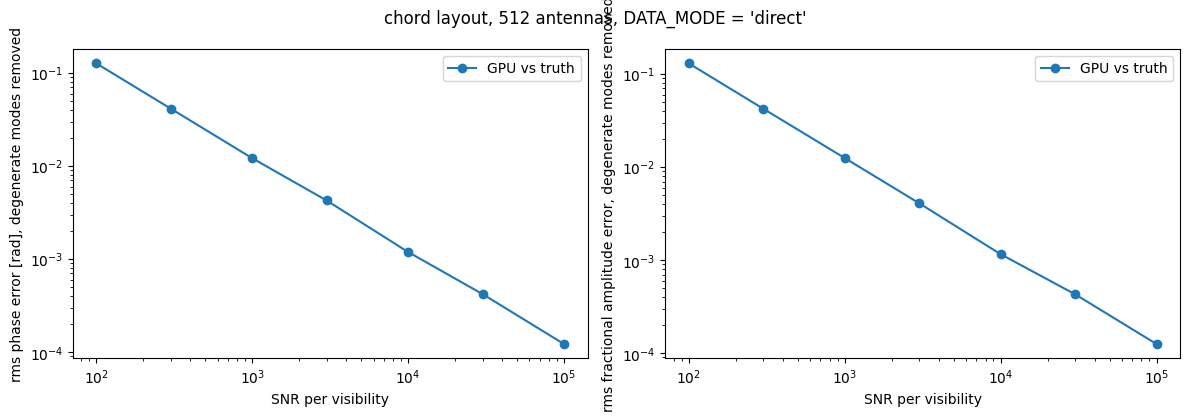

In [11]:
SNR_LIST, N_REAL = [1e2, 3e2, 1e3, 3e3, 1e4, 3e4, 1e5], 3
RUN_SWEEP = True
if RUN_SWEEP:
    backends = ["cpu", "gpu"] if (HAVE_CUPY and n_ant <= MAX_ANT_CPU) else [BACKEND]
    shape = (len(SNR_LIST), N_REAL)
    err_s = {(b, q): np.zeros(shape) for b in backends for q in ("amp", "phs")}
    gap = {q: np.zeros(shape) for q in ("amp", "phs")}
    rng_s = np.random.default_rng(SEED + 200)
    t0 = time.perf_counter()
    for i, snr in enumerate(SNR_LIST):
        dm, sm, sr = normalized_model(snr)
        for k in range(N_REAL):
            tg, ig = draw_gains(rng_s)
            d = make_data(tg, rng_s, dm, sr)                 # one dataset, used by every backend
            sol = {}
            for b in backends:
                sol[b], _, _ = calibrate(b, d, ig, dm, sm)
                e = degenerate_fit(sol[b], tg, antpos)
                err_s[b, "amp"][i, k], err_s[b, "phs"][i, k] = rms(e["amp_res"]), rms(e["phs_res"])
            if len(backends) == 2:
                e = degenerate_fit(sol["gpu"], sol["cpu"], antpos)
                gap["amp"][i, k], gap["phs"][i, k] = rms(e["amp_res"]), rms(e["phs_res"])
    print(f"sweep: {len(SNR_LIST) * N_REAL * len(backends)} solves in {time.perf_counter() - t0:.1f} s")

    snr = np.array(SNR_LIST)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, q, ylab in zip(axes, ("phs", "amp"), ("rms phase error [rad]", "rms fractional amplitude error")):
        for b, sty in zip(backends, ("o-", "s--")):
            ax.loglog(snr, err_s[b, q].mean(1), sty, label=f"{b.upper()} vs truth")
        if len(backends) == 2:
            ax.loglog(snr, gap[q].mean(1), "^-", label="GPU vs CPU")
        ax.set_xlabel("SNR per visibility"); ax.set_ylabel(ylab + ", degenerate modes removed"); ax.legend()
    fig.suptitle(f"{LAYOUT} layout, {n_ant} antennas, DATA_MODE = {DATA_MODE!r}")
    fig.tight_layout();